# Homework 4 — Evaluation Metrics for Classification

ML Zoomcamp 2026 · Module 4

Assignment: [cohorts/2026/homework/04-evaluation](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md)

Goal: evaluate a logistic regression model that predicts whether a lead signs up (`converted`) — ROC AUC, precision/recall, F1, K-fold CV and tuning `C`.

Due: **12 Oct 2026, 23:00 UTC**

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

%matplotlib inline

---
## Getting the data

In [2]:
!mkdir -p data && [ -f data/course_lead_scoring_2026.csv ] || curl -sSL -o data/course_lead_scoring_2026.csv \
    https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

In [3]:
df = pd.read_csv('data/course_lead_scoring_2026.csv')
print(df.shape)
df.head()

(5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


---
## Data preparation

* Check for missing values.
* Categorical features → `'NA'`; numerical features → `0.0`.

In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
categorical = list(df.select_dtypes(include='object').columns)
numerical = [c for c in df.columns if c not in categorical + ['converted']]
print(categorical)
print(numerical)

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
df.isnull().sum().sum()

['lead_source', 'industry', 'employment_status', 'location']
['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


np.int64(0)

---
## Split the data

Exact calls from the assignment (60 / 20 / 20, `random_state=1`).

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

features = categorical + numerical

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

---
## Q1. ROC AUC feature importance

Use each numerical variable as the score against `y_train`; if AUC < 0.5, negate the variable.

*Options: `lead_score` / `number_of_courses_viewed` / `interaction_count` / `annual_income`*

In [7]:
# Q1
aucs = {}
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
        c = f'-{c}'
    aucs[c] = auc

pd.Series(aucs, name='auc').sort_values(ascending=False).round(4).to_frame()

,auc
lead_score,0.7882
interaction_count,0.7649
number_of_courses_viewed,0.7230
annual_income,0.6082


---
## Q2. Training the model

One-hot encode with `DictVectorizer`, fit `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`, AUC on validation (3 decimals).

*Options: 0.532 / 0.632 / 0.732 / 0.832*

In [8]:
def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_tr, y_tr)
    return dv, model


def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [9]:
# Q2
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

auc = roc_auc_score(y_val, y_pred)
print(f"validation AUC = {auc:.4f} -> {round(auc, 3)}")

validation AUC = 0.7318 -> 0.732


---
## Q3. Precision and recall

Thresholds 0.0 → 1.0 (step 0.01). Ignore thresholds where both metrics are zero; pick the one with the smallest |precision − recall|.

*Options: 0.43 / 0.63 / 0.73 / 0.83*

In [10]:
thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)
actual_pos = (y_val == 1)
actual_neg = ~actual_pos

rows = []
for t in thresholds:
    pred_pos = (y_pred >= t)
    tp = (pred_pos & actual_pos).sum()
    fp = (pred_pos & actual_neg).sum()
    fn = (~pred_pos & actual_pos).sum()
    p = tp / (tp + fp) if tp + fp > 0 else 0.0
    r = tp / (tp + fn) if tp + fn > 0 else 0.0
    rows.append((t, tp, fp, fn, p, r))

df_scores = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'precision', 'recall'])

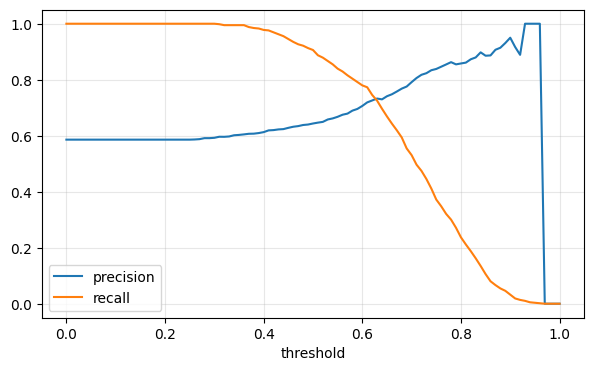

,threshold,tp,fp,fn,precision,recall,diff
63,0.63,425,155,161,0.732759,0.725256,0.007503
62,0.62,437,165,149,0.725914,0.745734,0.019820
64,0.64,408,151,178,0.729875,0.696246,0.033629
61,0.61,453,177,133,0.719048,0.773038,0.053990
65,0.65,392,137,194,0.741021,0.668942,0.072079


In [11]:
# Q3
plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
valid.sort_values('diff').head(5)

---
## Q4. F1 score

$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$ for every threshold; which one maximizes F1?

*Options: 0.21 / 0.41 / 0.61 / 0.81*

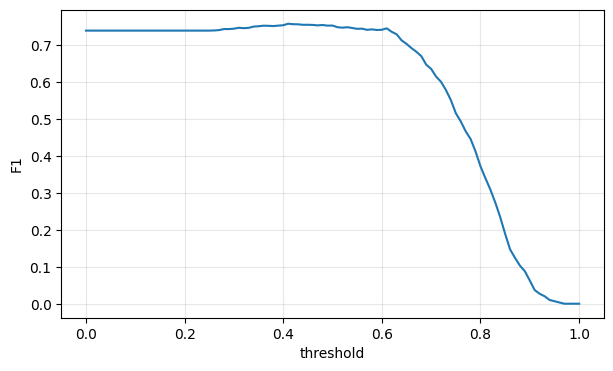

,threshold,tp,fp,fn,precision,recall,f1
41,0.41,572,352,14,0.619048,0.976109,0.757616
42,0.42,568,348,18,0.620087,0.969283,0.756325
43,0.43,564,342,22,0.622517,0.962457,0.756032
45,0.45,554,328,32,0.628118,0.945392,0.754768
44,0.44,560,338,26,0.623608,0.955631,0.754717


In [12]:
# Q4
p, r = df_scores.precision, df_scores.recall
df_scores['f1'] = (2 * p * r / (p + r)).fillna(0.0)

plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold'); plt.ylabel('F1'); plt.grid(alpha=0.3)
plt.show()

df_scores.sort_values('f1', ascending=False).head(5)

---
## Q5. 5-fold CV

`KFold(n_splits=5, shuffle=True, random_state=1)` over `df_full_train`, AUC per fold; std of the scores?

*Options: 0.001 / 0.007 / 0.013 / 0.060*

In [13]:
def cv_scores(C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv, model = train(df_tr, df_tr.converted.values, C=C)
        scores.append(roc_auc_score(df_va.converted.values, predict(df_va, dv, model)))
    return np.array(scores)

In [14]:
# Q5
scores = cv_scores(C=1.0)
print('fold AUCs:', scores.round(4))
print(f"mean = {scores.mean():.4f}, std = {scores.std():.4f} -> {round(scores.std(), 3)}")

fold AUCs: [0.7306 0.7296 0.7363 0.7412 0.7209]
mean = 0.7317, std = 0.0069 -> 0.007


---
## Q6. Hyperparameter tuning

`C` in `[0.000001, 0.001, 1]`, same KFold; mean and std rounded to 3 decimals. Ties → lowest std, then smallest `C`.

*Options: 0.000001 / 0.001 / 1*

In [15]:
# Q6
results = []
for C in [0.000001, 0.001, 1]:
    s = cv_scores(C=C)
    results.append((C, round(s.mean(), 3), round(s.std(), 3)))
    print(f"C={C:<8} mean = {s.mean():.3f} +- {s.std():.3f}")

pd.DataFrame(results, columns=['C', 'mean', 'std']).sort_values(['mean', 'std', 'C'], ascending=[False, True, True])

C=1e-06    mean = 0.617 +- 0.019


C=0.001    mean = 0.749 +- 0.010
C=1        mean = 0.732 +- 0.007


,C,mean,std
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
0,0.000001,0.617,0.019


---
## Answers

| Question | Answer | Computed value |
|---|---|---|
| Q1 — highest feature AUC | **`lead_score`** | 0.788 (vs 0.765 `interaction_count`, 0.723 `number_of_courses_viewed`, 0.608 `annual_income`) |
| Q2 — validation AUC | **0.732** | 0.7318 |
| Q3 — precision = recall | **0.63** | P 0.733, R 0.725 (\|diff\| 0.0075) |
| Q4 — max F1 threshold | **0.41** | F1 0.758 |
| Q5 — std of 5-fold AUC | **0.007** | 0.0069 (mean 0.732) |
| Q6 — best `C` | **0.001** | 0.749 ± 0.010 (vs 0.732 ± 0.007 at `C=1`, 0.617 ± 0.019 at `C=1e-6`) |

Notes:

- No numerical feature has AUC < 0.5, so nothing needed negating in Q1.
- `annual_income` is unscaled, which is why a stronger regularization (`C=0.001`) beats `C=1` in Q6.